# Multimodal Music Analysis

The target of this project is the implementation of a complete pipeline for extracting knowledge from music data by combining two different modalities: **Audio** and **Text**. The project is split into two parts:  
1. Preprocessing of the data, generation of embeddings and researching analysis.
2. Classification, Fusion and Evaluation.  
  
This notebook contains the implementation of part 2.

**Contributors**

|         Name         |          AM          |
| -------------------- | -------------------- |
| Διονύσιος Κοτσίρης   |   1115201900089      |
| Ιωάννης Οικονομίδης  |   1115201600120      |

Requirements:

In [ ]:
%pip install seaborn
%pip install datasets
%pip install matplotlib
%pip install vaderSentiment
%pip install kneed
%pip install contractions
%pip install pyspellchecker
%pip install scikit-learn
%pip install pandas
%pip install wordcloud
%pip install tensorflow
%pip install gensim
%pip install nltk

## 1. Classification Models

In [2]:
import pandas as pd
import os
import re

import numpy as np
import tensorflow as tf
import sklearn

import matplotlib.pyplot as plt

Firstly, we load the collected data from the part 1.
- The clean dataframe with the songs, genres, lyrics and MFCC stats.
- The audio and text embeddings  

In the first part, we completed a small case study by comparing the Autoencoder's and PCA's audio embeddings. In this part, we choose to work with the autoencoder's embeddings, because of their reduced dimensionality and high quality.

In [3]:
# Loading the data and the audio embeddings created in part 1.
final_df_path = "data/final_data.pkl"
if (os.path.isfile(path=final_df_path)):
    data = pd.read_pickle(final_df_path,)

data.head()

,id,genres,main_genre,song,tags,audio_stats,lyrics
0,006TYKNjNxWjfKjy,"[symphonic metal, symphonic power metal, power...",metal,Flames of Revenge,"symphonic metal,power metal,symphonic power metal","[23.30799674987793, -8.152815818786621, -17.38...",princess must assist death endur tragic pain c...
1,00i0OB17z3m3yamO,"[alternative metal, alternative rock, rock]",metal,Sign of the Times,"alternative rock,rock,alternative metal,altern...","[24.25779724121093, -10.212427139282228, -4.85...",sign time anoth mountain climb sun burn hot fl...
2,00mLjKFmaTv9MdaB,"[rap, hip hop, pop]",rap,Boom Boom Pow,"dance,hip hop,pop,hip-hop,rap","[20.77475357055664, -6.112589359283447, -10.24...",get get get get get get get get boom boom boom...
3,01ScM29f0wF2Mnkq,"[rap, indie pop, electronic]",rap,Implicit Demand for Proof,"electronic,alternative,rap,indie,indie pop","[21.80247497558593, 2.8943941593170166, -16.29...",know liar know could set fire day go ahead mak...
4,01gyRHLquwXDlhkO,[rap],rap,Somebody's Gotta Die,"rap,hip-hop,gangsta rap,east coast rap","[22.731481552124023, -12.233457565307615, 2.38...",sittin crib dreamin leer jet coup way salt sho...


In [4]:
audio_embeddings = np.load("data/audio_embeddings.npy")
audio_embeddings.shape

(17299, 32)

In [5]:
text_embeddings = np.load("data/text_embeddings.npy")
text_embeddings.shape

(17299, 100)

Next step, we set up the environment for the unimodal classification.
- exctracting the data and the labels
- choose and train classifier  
  
Since the embeddings are already fixed-size vector representations, classical classifiers such as SVM and Random Forest are more appropriate than RNNs or Transformers.  
  
We will train two different models (SVM and Random Forest classifier) and we will keep the one with the better metrics.

In [6]:
from sklearn.model_selection import  StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import LabelEncoder, StandardScaler, Normalizer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix, recall_score, precision_score, make_scorer
import seaborn as sns


In [19]:
# Preparing the data for the classifiers
X_text = text_embeddings
X_audio = audio_embeddings

le = LabelEncoder()
Y_LABELS = data["main_genre"]
Y_ENCODED = le.fit_transform(Y_LABELS)


In [20]:
'''
Function that trains the classifier
Args:
    - x_data: the training data
    - y_labels: labels corresponding to the data
    - available models: 
        - "svm" : SVM
        - "rf"  : Random Forest
Returns:
    - trained model
    - metrics
    - confusion matrix
'''
def genre_classifier(x_data, y_labels, classifier="svm"):

    cv = StratifiedKFold(
        n_splits=10,
        shuffle=True,
        random_state=42
    )

    scoring = {
        "accuracy": "accuracy",
        "precision": make_scorer(precision_score, average="macro", zero_division=0),
        "recall": make_scorer(recall_score, average="macro", zero_division=0),
        "f1": make_scorer(f1_score, average="macro", zero_division=0),
    }

    if classifier == "rf":
        model = RandomForestClassifier(
            n_estimators=300,
            max_depth=None,
            random_state=42,
            class_weight="balanced"
        )

    elif classifier == "svm":
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(kernel="rbf", C=10, gamma='auto', class_weight=None))
        ])

    else:
        print("Model is needed")
        return
    
    scores = cross_validate(
        model,
        x_data,
        y_labels,
        cv=cv,
        scoring=scoring,

    )

    # predictions across folds
    y_pred = cross_val_predict(
        model,
        x_data,
        y_labels,
        cv=cv,
        n_jobs=-1
    )

    print(f"{classifier} Accuracy: {scores['test_accuracy'].mean():.2f} ± {scores['test_accuracy'].std():.2f}")
    print(f"{classifier} Macro F1: {scores['test_f1'].mean():.2f} ± {scores['test_f1'].std():.2f}")
 
    print(classification_report(
        y_labels,
        y_pred,
        target_names=le.classes_
    ))
    
    conf_matrix = confusion_matrix(y_labels, y_pred)

 


    return model, scores, conf_matrix


### Model A: text classifier

In [21]:
''' SVM Classifier and Results for Text '''
svm_model_text, svm_scores_text, svm_matrix_text = genre_classifier(X_text, Y_ENCODED, classifier="svm")

svm Accuracy: 0.81 ± 0.01
svm Macro F1: 0.56 ± 0.01
              precision    recall  f1-score   support

   classical       0.00      0.00      0.00       614
        jazz       0.60      0.28      0.38      1525
       latin       0.73      0.64      0.68       883
       metal       0.81      0.95      0.88     10302
         rap       0.87      0.83      0.85      3975

    accuracy                           0.81     17299
   macro avg       0.60      0.54      0.56     17299
weighted avg       0.77      0.81      0.78     17299



In [22]:
''' Random Forest Classifier and Results for Text '''
rf_model_text, rf_scores_text, rf_matrix_text = genre_classifier(X_text, Y_ENCODED, classifier="rf")

rf Accuracy: 0.77 ± 0.01
rf Macro F1: 0.55 ± 0.01
              precision    recall  f1-score   support

   classical       0.27      0.88      0.41       614
        jazz       0.95      0.09      0.17      1525
       latin       0.79      0.33      0.47       883
       metal       0.83      0.90      0.86     10302
         rap       0.87      0.79      0.82      3975

    accuracy                           0.77     17299
   macro avg       0.74      0.60      0.55     17299
weighted avg       0.83      0.77      0.76     17299



### Model B: audio classifier

In [24]:
''' SVM Classifier and Results '''
svm_model_audio, svm_scores_audio, svm_matrix_audio = genre_classifier(X_audio, Y_ENCODED, classifier="svm")

svm Accuracy: 0.85 ± 0.01
svm Macro F1: 0.68 ± 0.02
              precision    recall  f1-score   support

   classical       0.65      0.51      0.57       614
        jazz       0.64      0.55      0.59      1525
       latin       0.52      0.40      0.45       883
       metal       0.90      0.95      0.92     10302
         rap       0.85      0.84      0.85      3975

    accuracy                           0.85     17299
   macro avg       0.71      0.65      0.68     17299
weighted avg       0.84      0.85      0.84     17299



In [ ]:
''' Random Forest Classifier and Results '''
rf_model_audio, rf_scores_audio, rf_matrix_audio = genre_classifier(X_audio, Y_ENCODED, classifier="rf")

rf Accuracy: 0.82 ± 0.01
rf Macro F1: 0.58 ± 0.02
              precision    recall  f1-score   support

   classical       0.75      0.25      0.38       614
        jazz       0.64      0.41      0.50      1525
       latin       0.68      0.20      0.32       883
       metal       0.86      0.95      0.91     10302
         rap       0.77      0.86      0.81      3975

    accuracy                           0.82     17299
   macro avg       0.74      0.54      0.58     17299
weighted avg       0.81      0.82      0.80     17299



#### Evaluation of Classification Models
As we explained above, we experiment on two different classifiers, **SVM** and **Random Forest Classifier**, for the text and the audio embeddings. We tried different combinations of hyperparameters for both classifiers, in order to take the best of them. **SVM** outperforms the other in most metrics, so it will be the primary classifier for the comparison of Model A (text) and B (audio) and also for the fused model that we present in the next section.

## 2. Multimodal Fusion

## 3. Evaluation


In the section 1, we present the comparison of two classifiers and we decide to keep the SVM as the stronger one for both text and audio. We make the variables' names more meaningful:
- Model A (Text-only) 
- Model B (Audio-only)
- Model C (Fused)

In [13]:
# Text-only model
model_A, scores_A, conf_matrix_A = svm_model_text, svm_scores_text, svm_matrix_text

# Audio-only model
model_B, scores_B, conf_matrix_B = svm_model_audio, svm_scores_audio, svm_matrix_audio

The following functions will help us with the evaluation and visualisation of the results of the respective models.

In [14]:
# Total report for the models
def model_report(scores):
    results = {
        "Metric": [
            "Fit Time",
            "Score Time",
            "Accuracy",
            "Precision",
            "Recall",
            "Macro F1"
        ],
        "Mean": [
            scores["fit_time"].mean(),
            scores["score_time"].mean(),
            scores["test_accuracy"].mean(),
            scores["test_precision"].mean(),
            scores["test_recall"].mean(),
            scores["test_f1"].mean()
        ],
        "Std": [
            scores["fit_time"].std(),
            scores["score_time"].std(),
            scores["test_accuracy"].std(),
            scores["test_precision"].std(),
            scores["test_recall"].std(),
            scores["test_f1"].std()
        ]
    }

    df = pd.DataFrame(results)
    df["Result"] = df["Mean"].round(3).astype(str) + " ± " + df["Std"].round(3).astype(str)

    print(df[["Metric", "Result"]])

In [15]:
# visualization of the confusion matrix
def conf_matrix_heatmap(matrix, y_labels):
    labels = np.unique(y_labels)

    plt.figure(figsize=(8,6))
    sns.heatmap(matrix, annot=True,
                fmt="g", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels)
    plt.title("Confusion Matrix Heatmap")
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.tight_layout()
    plt.show()

### MODEL A: text-only

In [16]:
model_report(scores_A)

       Metric         Result
0    Fit Time  5.368 ± 0.214
1  Score Time  0.775 ± 0.013
2    Accuracy  0.812 ± 0.007
3   Precision   0.602 ± 0.01
4      Recall  0.539 ± 0.014
5    Macro F1  0.556 ± 0.014


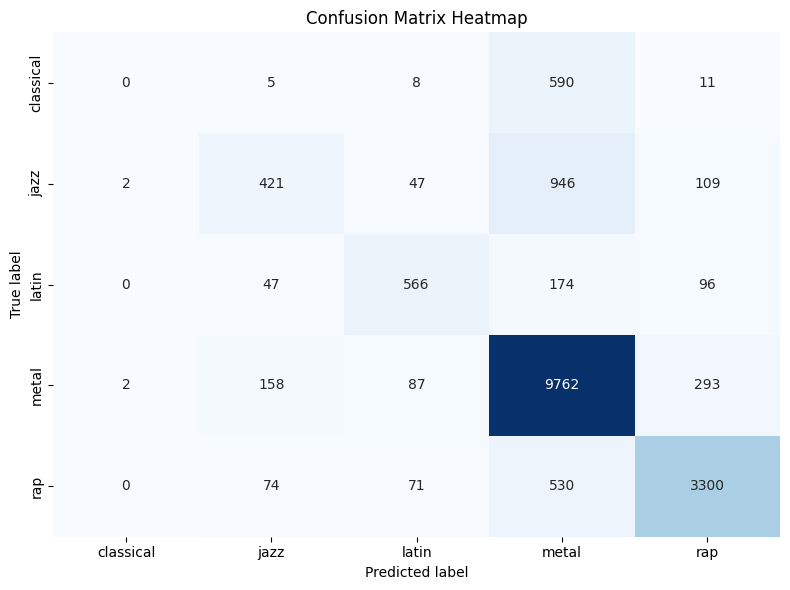

In [ ]:
conf_matrix_heatmap(conf_matrix_A, Y_LABELS)

### MODEL B: audio-only

In [25]:
model_report(scores_B)

       Metric         Result
0    Fit Time  2.726 ± 0.147
1  Score Time   0.511 ± 0.02
2    Accuracy  0.845 ± 0.009
3   Precision  0.713 ± 0.024
4      Recall  0.649 ± 0.024
5    Macro F1  0.676 ± 0.024


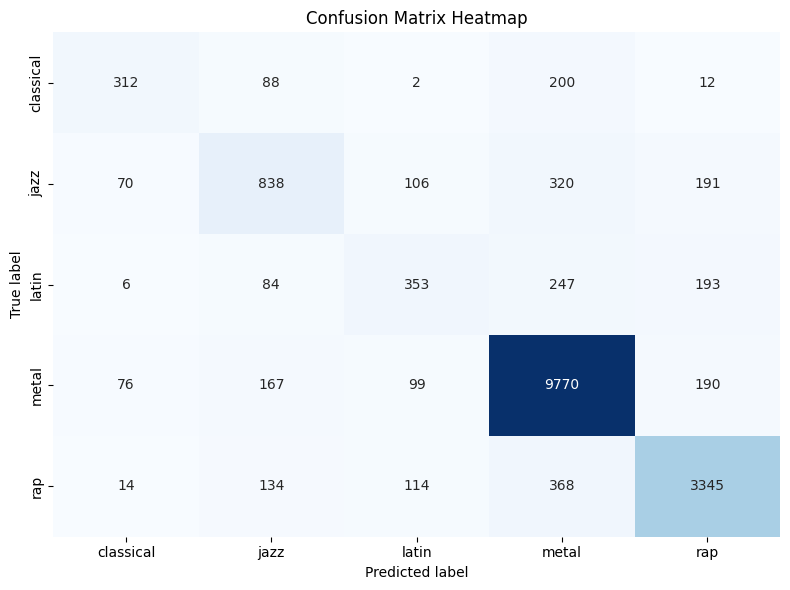

In [26]:
conf_matrix_heatmap(conf_matrix_B, Y_LABELS)

### MODEL C: fused

### Bar chart : Audio vs Text vs Combined

In [38]:
# Creating the dataframe for the bar chart
# Models and F1 scores

data = {
    "Model"    : ["A", "B", "C"],
    "F1 score" : [scores_A['test_f1'].mean(), scores_B['test_f1'].mean(), 0],
}

df_f1 = pd.DataFrame(data=data)
df_f1
# float(scores_A['test_f1'].mean())

,Model,F1 score
0,A,0.556256
1,B,0.676122
2,C,0.000000


<Axes: xlabel='Model', ylabel='F1 score'>

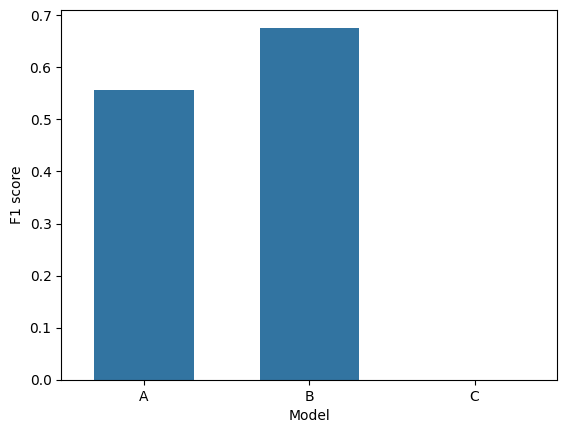

In [41]:
sns.barplot(df_f1, x="Model", y="F1 score", width=0.6)